In [1]:
import matplotlib.pyplot as plot
import pandas
import seaborn
import re
import numpy as np
from scipy import stats

seaborn.set_theme(style='ticks', context='paper', palette='plasma')

LEADS_PATH, PEDIDOS_PATH = '../data/churn_aplicacao_leads_final.csv', '../data/churn_comportamental_pedidos_final.csv'

In [2]:
leads = pandas.read_csv(LEADS_PATH)
pedidos = pandas.read_csv(PEDIDOS_PATH)

In [3]:
leads.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 19 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   id_cliente                       2000 non-null   int64  
 1   uf                               2000 non-null   object 
 2   municipio                        2000 non-null   object 
 3   segmento_cliente                 2000 non-null   object 
 4   natureza_juridica                2000 non-null   object 
 5   fonte_cliente                    2000 non-null   object 
 6   cnae_codigo                      2000 non-null   object 
 7   capital_social                   2000 non-null   object 
 8   idade_cnpj                       2000 non-null   object 
 9   serasa_contagem_negativacoes     2000 non-null   float64
 10  serasa_contagem_protestos        2000 non-null   float64
 11  serasa_credores                  190 non-null    object 
 12  serasa_socio_tem_neg

In [4]:
pedidos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4441 entries, 0 to 4440
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id_pedido     4441 non-null   int64 
 1   id_cliente    4441 non-null   int64 
 2   valor         4438 non-null   object
 3   produtos      4440 non-null   object
 4   data_entrega  4441 non-null   object
dtypes: int64(2), object(3)
memory usage: 173.6+ KB


Cruzando a tabela de leads com a de pedidos:

In [5]:
joined = leads.merge(right=pedidos, on='id_cliente', how='left')

Análise estrutural dos dados:

In [6]:
joined.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5441 entries, 0 to 5440
Data columns (total 23 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   id_cliente                       5441 non-null   int64  
 1   uf                               5441 non-null   object 
 2   municipio                        5441 non-null   object 
 3   segmento_cliente                 5441 non-null   object 
 4   natureza_juridica                5441 non-null   object 
 5   fonte_cliente                    5441 non-null   object 
 6   cnae_codigo                      5441 non-null   object 
 7   capital_social                   5441 non-null   object 
 8   idade_cnpj                       5441 non-null   object 
 9   serasa_contagem_negativacoes     5441 non-null   float64
 10  serasa_contagem_protestos        5441 non-null   float64
 11  serasa_credores                  447 non-null    object 
 12  serasa_socio_tem_neg

Porcentagem de faltantes por coluna:

In [7]:
print('faltantes por atributo em LEADS')
for label in leads.columns:
    column: pandas.Series = leads[label]
    missing_pct = 100 * column.isna().sum() / column.size
    
    if missing_pct > 0:
        print(f'{label:32s} | {missing_pct:.2f}% ({column.isna().sum()}/{column.size})')

faltantes por atributo em LEADS
serasa_credores                  | 90.50% (1810/2000)
ifood_contagem_avaliacoes        | 94.30% (1886/2000)
ifood_faixa_preco                | 87.85% (1757/2000)
google_maps_avaliacao            | 97.80% (1956/2000)
google_maps_contagem_avaliacoes  | 91.25% (1825/2000)
google_maps_tem_website          | 91.25% (1825/2000)


- Muitos faltantes
- `google_maps_tem_website` é só uma flag booleana
- Se você não tiver website no google maps, você não vai ter avaliações
- Se você não tiver ifood, não terá faixa de preço nem avaliações
- Tudo bem não ter credores no serasa

In [8]:
print('faltantes por atributo em PEDIDOS')
for label in pedidos.columns:
    column: pandas.Series = pedidos[label]
    missing_pct = 100 * column.isna().sum() / column.size
        
    if missing_pct > 0:
        print(f'{label:32s} | {missing_pct:.2f}% ({column.isna().sum()}/{column.size})')

faltantes por atributo em PEDIDOS
valor                            | 0.07% (3/4441)
produtos                         | 0.02% (1/4441)


Quantidade de ocorrências de cada cliente na tabela de pedidos:

In [9]:
pedidos.id_cliente.value_counts()

id_cliente
1739936841220    56
8113331192324    46
7243866379881    44
1560063946241    29
1222295907587    29
                 ..
6388676592025     1
1972150366050     1
2150548890639     1
5283377970744     1
1834318012896     1
Name: count, Length: 1000, dtype: int64

IDs dos clientes cujos pedidos tem `valor` ou `produtos`  nulos:

In [10]:
pedidos[pedidos.valor.isna() | pedidos.produtos.isna()]

,id_pedido,id_cliente,valor,produtos,data_entrega
1754,3651192517370,5284965822687,NaN,"(0, 5]",2024-11-07
3566,8540620592324,6829726356717,NaN,"(0, 5]",2024-10-06
3603,9279195172130,8400679696018,NaN,NaN,2024-09-10


Avaliando cada um desses clientes

In [ ]:
def extrair_numero(texto):
    if pandas.isna(texto):
        return np.nan
    numeros = re.findall(r'\d+', str(texto))
    if len(numeros) == 2:
        return (float(numeros[0]) + float(numeros[1])) / 2
    return np.nan
clientes_alvo = pedidos[pedidos['valor'].isna() | pedidos['produtos'].isna()]['id_cliente'].unique()
pedidos_filtrados = pedidos[pedidos['id_cliente'].isin(clientes_alvo)].copy()
pedidos_filtrados['valor_numerico'] = pedidos_filtrados['valor'].apply(extrair_numero)

# Clientes que tem valores ou produtos faltando
print("=== HISTÓRICO COMPLETO SEPARADO POR CLIENTE ===")
for id_cliente, dados_do_cliente in pedidos_filtrados.groupby('id_cliente'):
    print(f"\n---> Mostrando todos os pedidos do Cliente ID: {id_cliente}")
    # Usamos o display para mostrar a tabela original bonitinha no notebook
    display(dados_do_cliente[['id_pedido', 'id_cliente', 'valor', 'produtos', 'data_entrega']])

=== HISTÓRICO COMPLETO SEPARADO POR CLIENTE ===

---> Mostrando todos os pedidos do Cliente ID: 5284965822687


,id_pedido,id_cliente,valor,produtos,data_entrega
1749,1582631733956,5284965822687,"(0, 500]","(0, 5]",2024-09-03
1750,5354552944002,5284965822687,"(0, 500]","(0, 5]",2024-09-23
1751,9144766761347,5284965822687,"(0, 500]","(0, 5]",2024-09-24
1752,3328300994554,5284965822687,"(0, 500]","(0, 5]",2024-10-03
1753,5941252653560,5284965822687,"(0, 500]","(0, 5]",2024-10-18
1754,3651192517370,5284965822687,NaN,"(0, 5]",2024-11-07
1755,7252566720763,5284965822687,"(0, 500]","(0, 5]",2024-11-26
1756,9727236830584,5284965822687,"(500, 1000]","(0, 5]",2024-11-29



---> Mostrando todos os pedidos do Cliente ID: 6829726356717


,id_pedido,id_cliente,valor,produtos,data_entrega
3563,6272749168717,6829726356717,"(0, 500]","(0, 5]",2024-09-01
3564,4585565864108,6829726356717,"(500, 1000]","(5, 10]",2024-09-14
3565,3725217882172,6829726356717,"(1000, 2000]","(10, 10000000]",2024-10-01
3566,8540620592324,6829726356717,NaN,"(0, 5]",2024-10-06
3567,2056586441380,6829726356717,"(0, 500]","(5, 10]",2024-10-13
3568,8643811795861,6829726356717,"(0, 500]","(0, 5]",2024-10-23
3569,7028977447207,6829726356717,"(0, 500]","(5, 10]",2024-10-30



---> Mostrando todos os pedidos do Cliente ID: 8400679696018


,id_pedido,id_cliente,valor,produtos,data_entrega
3603,9279195172130,8400679696018,NaN,NaN,2024-09-10
3604,5457457823905,8400679696018,"(0, 500]","(0, 5]",2024-09-10
3605,7792309100909,8400679696018,"(0, 500]","(0, 5]",2024-09-11
3606,4982714257226,8400679696018,"(0, 500]","(0, 5]",2024-09-12
3607,6587934300674,8400679696018,"(0, 500]","(0, 5]",2024-10-10
3608,3720208144101,8400679696018,"(0, 500]","(0, 5]",2024-10-21
3609,8917394309716,8400679696018,"(0, 500]","(0, 5]",2024-11-06
3610,2460371003704,8400679696018,"(0, 500]","(0, 5]",2024-11-12
3611,9161077679880,8400679696018,"(0, 500]","(0, 5]",2024-11-29
3612,1405173884259,8400679696018,"(0, 500]","(0, 5]",2024-11-29


Contando quantidade de cada valor únicos para atributos 'valor' e 'produtos' em pedidos

In [12]:
contagem_valor = pedidos['valor'].value_counts(dropna=False)

print("=== Quantidade de instâncias para cada valor na coluna 'valor' ===")
display(contagem_valor)

contagem_produtos = pedidos['produtos'].value_counts(dropna=False)

print("\n=== Quantidade de instâncias para cada valor na coluna 'produtos' ===")
display(contagem_produtos)

=== Quantidade de instâncias para cada valor na coluna 'valor' ===


valor
(0, 500]            3361
(500, 1000]          713
(1000, 2000]         230
(2000, 10000000]     134
NaN                    3
Name: count, dtype: int64


=== Quantidade de instâncias para cada valor na coluna 'produtos' ===


produtos
(0, 5]            3885
(5, 10]            446
(10, 10000000]     109
NaN                  1
Name: count, dtype: int64

Avaliando correlação entre valores de 'valor' e 'produto'

In [13]:
#Tabela de Contingência
print("=== TABELA CRUZADA (QUANTIDADE DE COMBINAÇÕES) ===")
tabela_cruzada = pandas.crosstab(pedidos['valor'], pedidos['produtos'])
display(tabela_cruzada)

#Correlação Matemática
pedidos_analise = pedidos.copy()

pedidos_analise['valor_num'] = pedidos_analise['valor'].apply(extrair_numero)
pedidos_analise['produtos_num'] = pedidos_analise['produtos'].apply(extrair_numero)

correlacao = pedidos_analise['valor_num'].corr(pedidos_analise['produtos_num'])

print("\n=== CORRELAÇÃO MATEMÁTICA ===")
print(f"O índice de correlação entre Valor e Produtos é: {correlacao:.4f}")

=== TABELA CRUZADA (QUANTIDADE DE COMBINAÇÕES) ===


produtos,"(0, 5]","(10, 10000000]","(5, 10]"
valor,,,
"(0, 500]",3106,17,238
"(1000, 2000]",168,39,23
"(2000, 10000000]",114,13,7
"(500, 1000]",495,40,178



=== CORRELAÇÃO MATEMÁTICA ===
O índice de correlação entre Valor e Produtos é: 0.0827


Visualizando tudo isso em gráfico e matriz

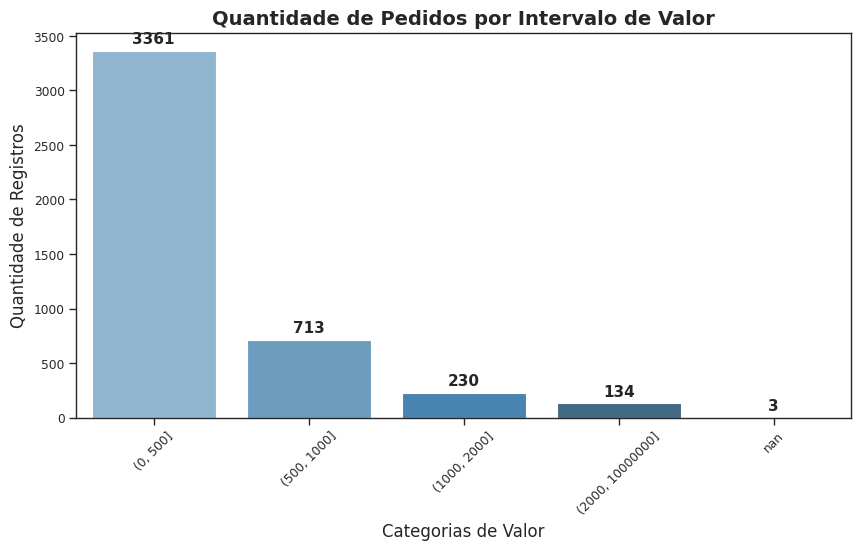

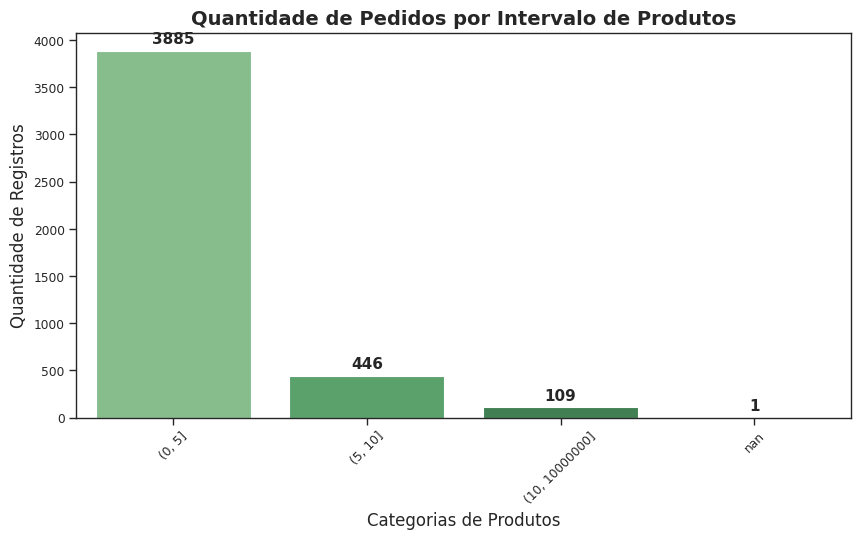

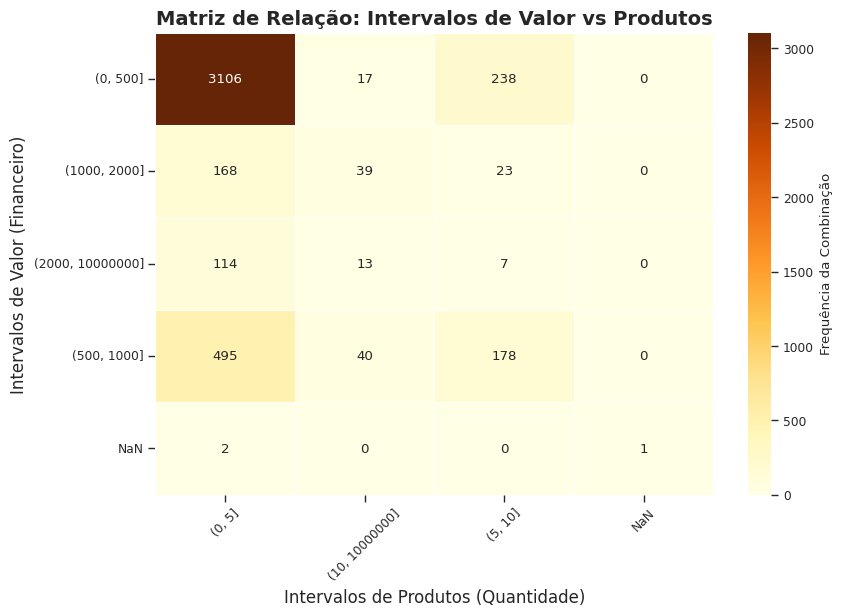

In [14]:
#Contagem da coluna 'valor' com os números no topo
plot.figure(figsize=(10, 5))
contagem_valor = pedidos['valor'].value_counts(dropna=False)

ax1 = seaborn.barplot(
    x=contagem_valor.index.astype(str),
    y=contagem_valor.values,
    hue=contagem_valor.index.astype(str),
    palette="Blues_d",
    legend=False
)

for container in ax1.containers:
    ax1.bar_label(container, fontsize=11, padding=3, fontweight='bold')

plot.title("Quantidade de Pedidos por Intervalo de Valor", fontsize=14, fontweight='bold')
plot.xlabel("Categorias de Valor", fontsize=12)
plot.ylabel("Quantidade de Registros", fontsize=12)
plot.xticks(rotation=45)
plot.show()


#Contagem da coluna 'produtos' com os números no topo
plot.figure(figsize=(10, 5))
contagem_produtos = pedidos['produtos'].value_counts(dropna=False)

ax2 = seaborn.barplot(
    x=contagem_produtos.index.astype(str),
    y=contagem_produtos.values,
    hue=contagem_produtos.index.astype(str),
    palette="Greens_d",
    legend=False
)

for container in ax2.containers:
    ax2.bar_label(container, fontsize=11, padding=3, fontweight='bold')

plot.title("Quantidade de Pedidos por Intervalo de Produtos", fontsize=14, fontweight='bold')
plot.xlabel("Categorias de Produtos", fontsize=12)
plot.ylabel("Quantidade de Registros", fontsize=12)
plot.xticks(rotation=45)
plot.show()


#Mapa de Calor (Relação entre os Intervalos literais)
tabela_cruzada = pandas.crosstab(
    pedidos['valor'].fillna('NaN').astype(str),
    pedidos['produtos'].fillna('NaN').astype(str)
)

plot.figure(figsize=(9, 6))

seaborn.heatmap(
    tabela_cruzada,
    annot=True,
    fmt="d",
    cmap="YlOrBr",
    linewidths=0.5,
    cbar_kws={'label': 'Frequência da Combinação'}
)

plot.title("Matriz de Relação: Intervalos de Valor vs Produtos", fontsize=14, fontweight='bold')
plot.xlabel("Intervalos de Produtos (Quantidade)", fontsize=12)
plot.ylabel("Intervalos de Valor (Financeiro)", fontsize=12)
plot.xticks(rotation=45)
plot.show()

- Temos que achar uma maneira de imputar esses valores com base nos outros pedidos desses clientes

Contando valores únicos para cada atributo:

In [15]:
for label in joined.columns:
    column: pandas.Series = joined[label]

    # Contando os valores únicos:
    unique_values = column.unique()
    print(f'{label:32s} | {unique_values.size!s:5s}', end='')

    # Imprimindo os valores possíveis para
    # os atributos somente se são poucos:
    if unique_values.size <= 20:
        values_str = ', '.join(str(v) for v in unique_values)
        print(f'({values_str})', end='')

    print()

id_cliente                       | 2000 
uf                               | 1    (CE)
municipio                        | 31   
segmento_cliente                 | 21   
natureza_juridica                | 4    (206-2 - Sociedade Empresária Limitada, 213-5 - Empresário (Individual), 230-5 - Empresa Individual de Responsabilidade Limitada (de Natureza Empresária), 224-0 - Sociedade Simples Limitada)
fonte_cliente                    | 5    (Fonte 5, Fonte 1, Fonte 3, Fonte 2, Fonte 4)
cnae_codigo                      | 107  
capital_social                   | 19   ((70000, 100000], (3000, 5000], (8000, 10000], (200000, 1000000], (15000, 20000], (50000, 70000], (30000, 50000], (5000, 8000], (100000, 200000], (20000, 30000], (1000000, 10000000], (10000, 15000], (0, 1], (1500, 2000], (200, 1000], (1, 200], (1000, 1500], (2000, 3000], (10000000, 100000000000])
idade_cnpj                       | 20   ((8000, 25000], (5000, 8000], (1300, 1600], (2000, 2400], (50, 100], (2400, 3000], (4000, 5000],

- Só tem um estado (CE)
- `google_maps_tem_website` tem valores (1.0, nan).
- `google_maps_avaliacao` não tem valor no intervalo `(4.0, 4.5]`
- `capital_social`, `idade_cnpj`, `ifood_contagem_avaliacoes`, `valor` (pedido) e `produtos` (pedido) são dados em 

In [16]:
#Hierarquia do CNAE no estilo do dataset:
# AA -> divisão
# AA.B -> grupo
# AA.BC-C -> classe
# AA.BC-C-DD -> subclasse

# Contando divisões únicas
divisoes = {cnae[:2] for cnae in leads.cnae_codigo}

print(f'quantidade de divisões CNAE: {len(divisoes)} | {sorted(divisoes)}')
print(f'exemplos de alguns códigos: {sorted(leads.cnae_codigo)[:5]}')

quantidade de divisões CNAE: 27 | ['12', '14', '20', '23', '24', '25', '29', '30', '33', '36', '37', '38', '39', '52', '53', '64', '70', '74', '76', '77', '78', '81', '83', '85', '93', '96', '97']
exemplos de alguns códigos: ['12.10-3-97', '12.74-7-12', '12.74-7-32', '12.74-7-79', '14.17-3-90']


- Segundo detalhamento da IBGE/CONCLA dos [códigos CNAE 2.3](https://cnae.ibge.gov.br/images/concla/documentacao/CNAE_Subclasses_2_3_Estrutura_Detalhada.xlsx), não existe o código `12.10-3/97` por exemplo
- Não podemos contar que esses valores tenham significado explícito 
- O Notion dizia que podemos contar com a hierarquia dos códigos, mas o que isso significa?

In [17]:
print(f'quantidade de valores únicos para credores serasa: {leads.serasa_credores.nunique()}')
print(f'lista de credores: {sorted(leads.serasa_credores.dropna().unique())}')

quantidade de valores únicos para credores serasa: 49
lista de credores: ['Alimentos e Bebidas', 'Alimentos e Bebidas, Alimentos e Bebidas, Alimentos e Bebidas', 'Alimentos e Bebidas, Bancos e Financeiro', 'Alimentos e Bebidas, Bancos e Financeiro, Alimentos e Bebidas', 'Alimentos e Bebidas, Bancos e Financeiro, Bancos e Financeiro, Financeiro, Alimentos e Bebidas, Alimentos e Bebidas, Indústria', 'Alimentos e Bebidas, Saúde', 'Alimentos e Bebidas, Tecnologia e Pagamentos', 'Bancos e Financeiro', 'Bancos e Financeiro, Alimentos e Bebidas, Bancos e Financeiro', 'Bancos e Financeiro, Alimentos e Bebidas, Distribuição', 'Bancos e Financeiro, Bancos e Financeiro', 'Bancos e Financeiro, Bancos e Financeiro, Bancos e Financeiro', 'Bancos e Financeiro, Bancos e Financeiro, Telecomunicações, Contabilidade', 'Bancos e Financeiro, Comunicação', 'Bancos e Financeiro, Financeiro', 'Bancos e Financeiro, Tecnologia e Pagamentos', 'Bancos e Financeiro, Tecnologia e Pagamentos, Bancos e Financeiro', '

- Não existem 49 valores diferentes de fato, são uma lista de valores separados por vírgulas
- Existem listas com valores repetidos, pq?
- É preciso olhar valor por valor para decidir como separar os valores únicos de cada lista de fato:

> Serasa_credores: Até 5 empresas diferentes para as quais o cliente deve. Se o cliente dever para mais de 5 empresas diferentes, as 5 mais recentes serão exibidas. Os dados estão anonimizados, identificando apenas o segmento de cada um dos credores (ex. Comércio). No caso do cliente não dever para outra empresa, o campo é nulo.

In [18]:
credores: set[str] = set()

for credor in leads.serasa_credores.dropna().unique():
    credores.update(credor.split(', '))

print(f'{len(credores)} categorias únicas de credores:')
sorted(credores)

21 categorias únicas de credores:


['Alimentos e Bebidas',
 'Bancos e Financeiro',
 'Comunicação',
 'Comércio',
 'Contabilidade',
 'Distribuição',
 'Diversos',
 'Energia',
 'Financeiro',
 'Imobiliário',
 'Indústria',
 'Logística',
 'Saúde',
 'Seguros e Financeiro',
 'Serviços',
 'Serviços Ambientais',
 'Tecnologia',
 'Tecnologia e Pagamentos',
 'Telecomunicações',
 'Varejo',
 'Viagens e Turismo']

só verificando se esses são categóricos ou não msm

In [19]:
leads.serasa_contagem_negativacoes.unique()

array([  0.,  14.,   6.,   2.,   1.,   3.,   4.,  10.,  15.,  16.,  19.,
         7.,   5.,  11.,  22.,  52.,   8.,   9., 223.,  12.,  25.,  29.,
        30.,  33.,  21., 162.,  99.])

In [20]:
leads.segmento_cliente.unique()

array(['Segmento 5', 'Segmento 19', 'Segmento 20', 'Segmento 13',
       'Segmento 18', 'Segmento 14', 'Segmento 3', 'Segmento 10',
       'Segmento 15', 'Segmento 4', 'Segmento 16', 'Segmento 8',
       'Segmento 6', 'Segmento 9', 'Segmento 17', 'Segmento 2',
       'Segmento 21', 'Segmento 7', 'Segmento 1', 'Segmento 11',
       'Segmento 12'], dtype=object)

In [21]:
datas = pedidos.data_entrega
# pegando o período das datas de entregas
meses: set[str] = {date[:7] for date in datas.dropna().unique()}

print(f'meses: {sorted(meses)}')
print(f'quantidade de pedidos sem data de entrega: {datas.isna().sum()}')

meses: ['2024-09', '2024-10', '2024-11', '2024-12']
quantidade de pedidos sem data de entrega: 0


- Quando formos treinar um modelo, devemos ordenar por data e deixarmos os dados dos pedidos dos ultimos dias para teste

In [22]:
print(f'quantidade de entradas na tabela de leads sem pedidos: {joined.data_entrega.isna().sum()}')

quantidade de entradas na tabela de leads sem pedidos: 1000


---

# Análise univariada

In [23]:
def sort_by_range(values: list[str], *, is_float = False):
    """Ordena intervalos numéricos escritos por extenso"""

    range_type = float if is_float else int
    
    ranges = sorted(
        [range_type(v) for v in range[1:-1].split(', ')]
        for range in values
    )

    return [
        f'({a}, {b}]' for a, b in ranges
    ]

Variáveis de intervalo:

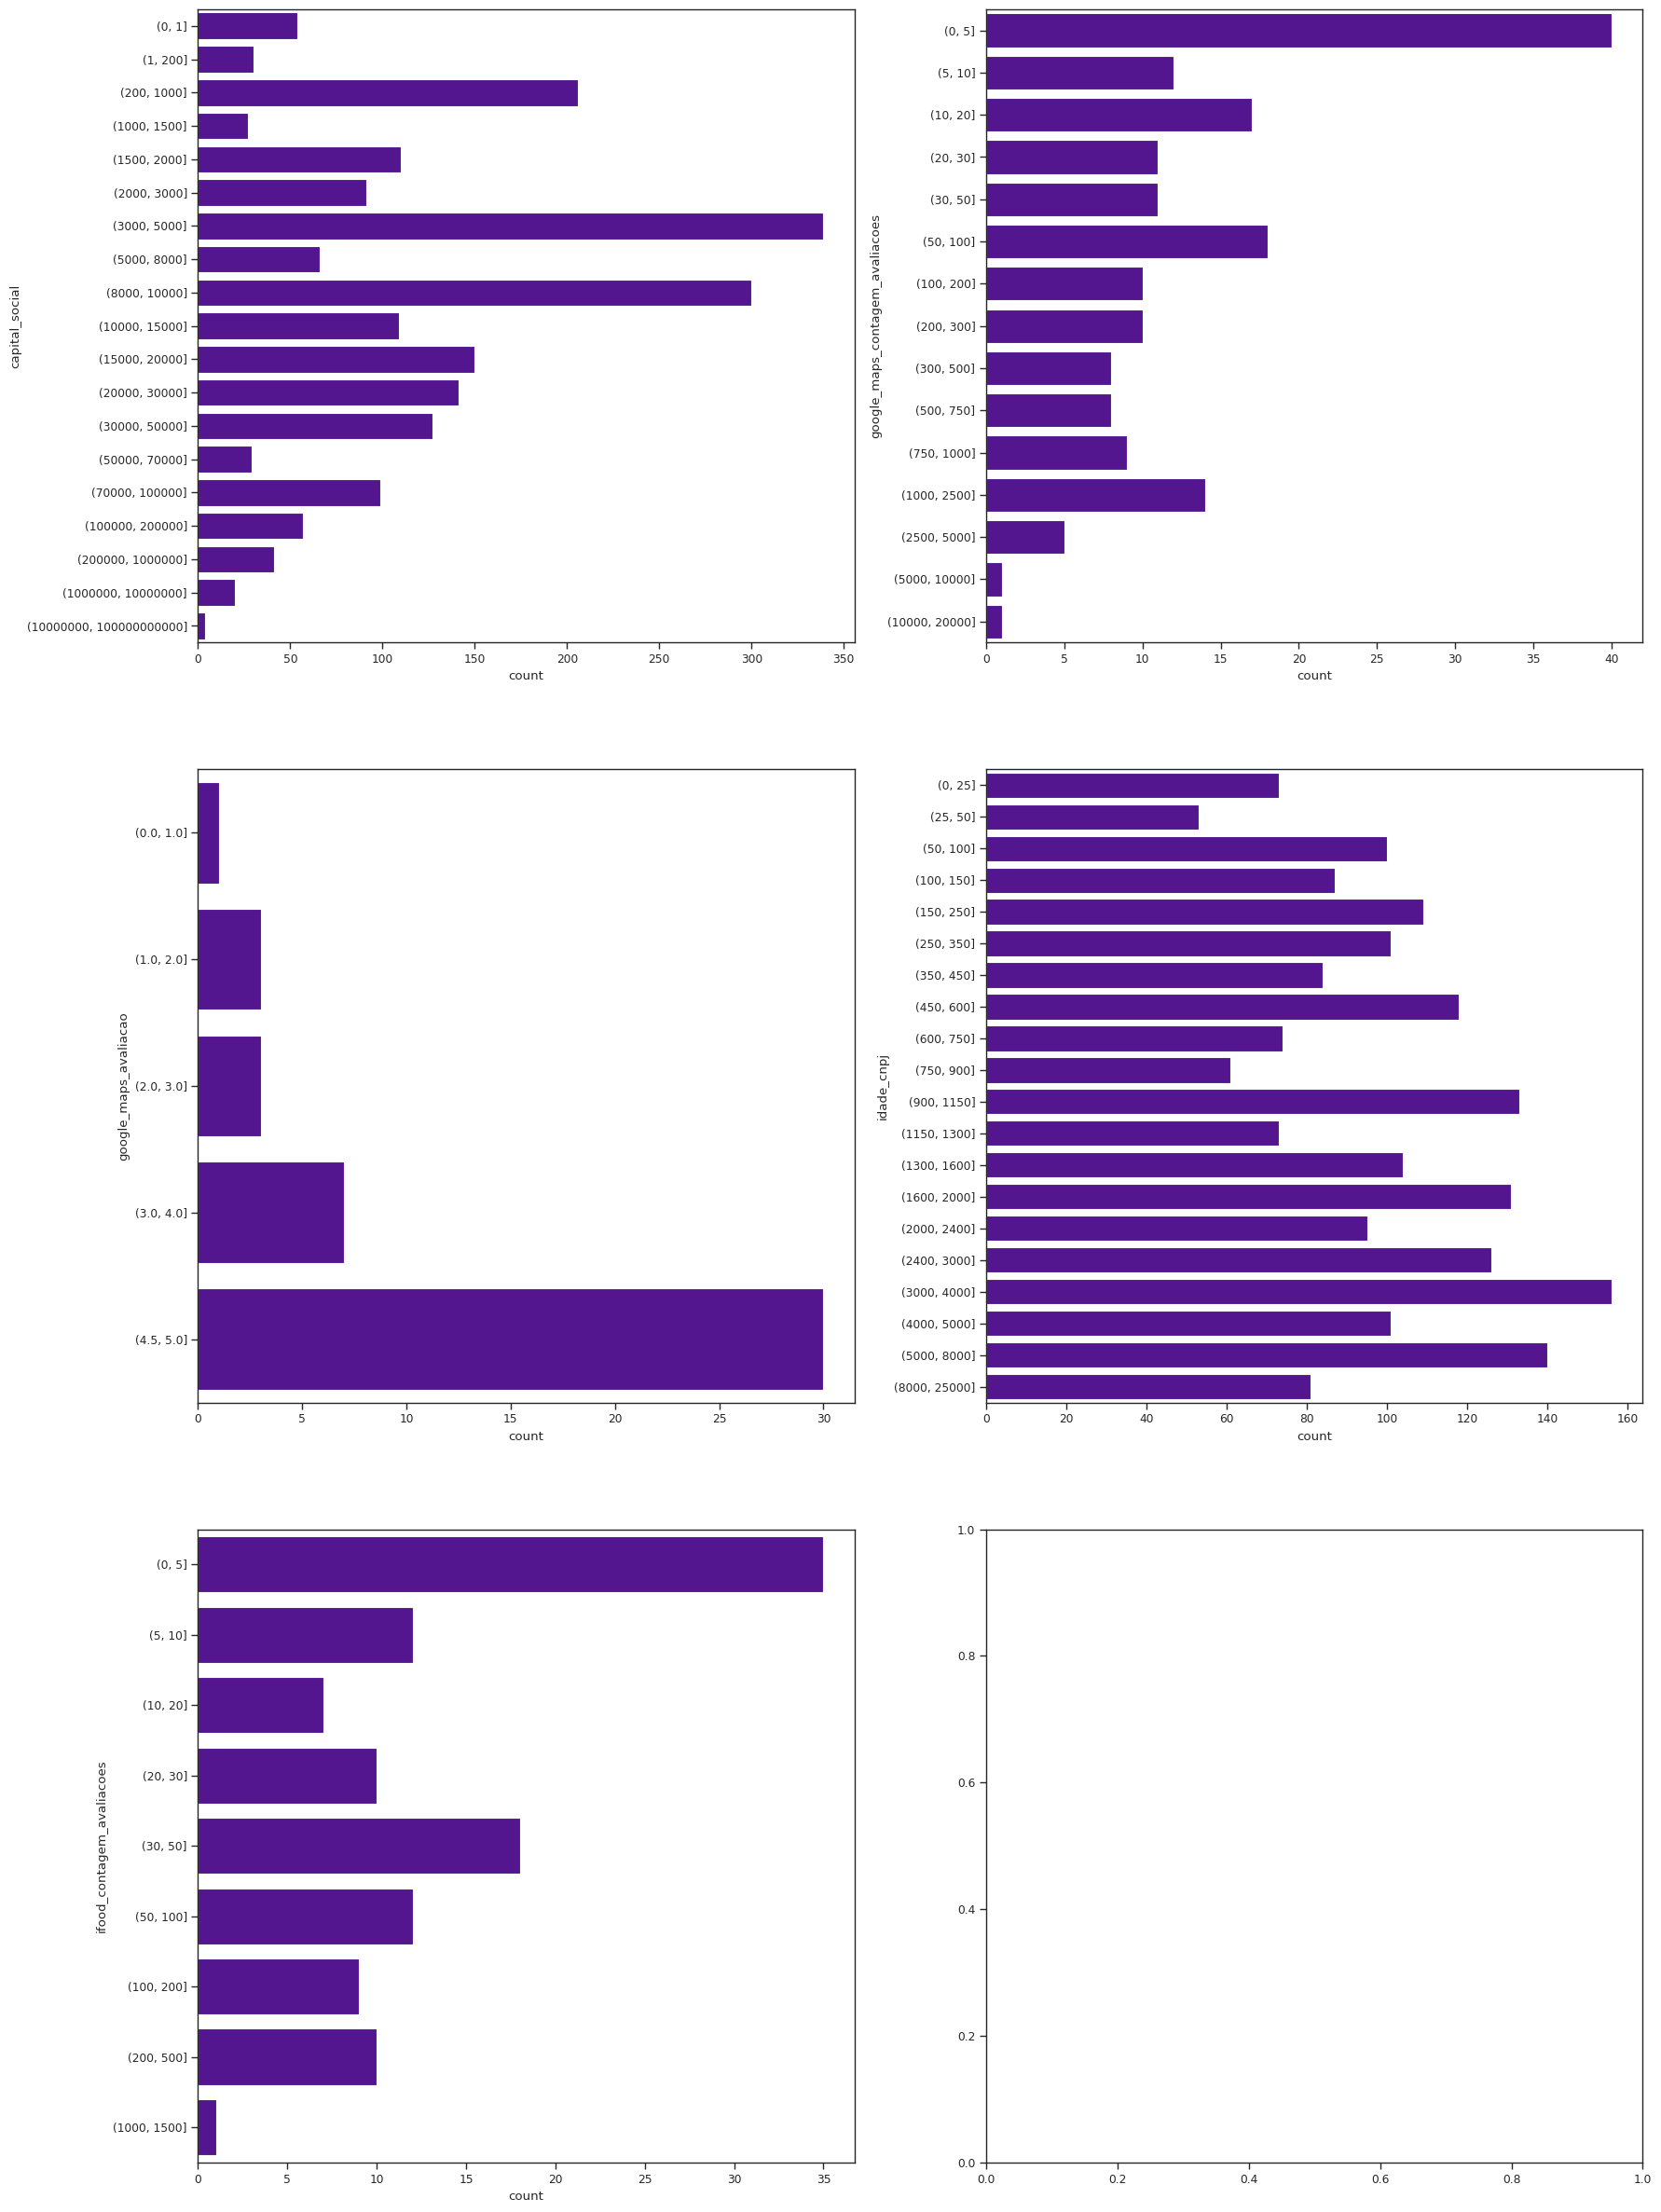

In [24]:
axes = plot.figure(figsize=(20, 30)).subplots(3, 2)

features = ['capital_social', 'idade_cnpj', 'ifood_contagem_avaliacoes', 'google_maps_contagem_avaliacoes', 'google_maps_avaliacao']

for i in range(5):
    feature, ax = features[i], axes[i % 3][i % 2]
    is_float = feature in ('google_maps_avaliacao')
    seaborn.countplot(
        data=leads,
        y=feature,
        order=sort_by_range(leads[feature].dropna().unique(), is_float=is_float),
        ax=ax
    )

<Axes: xlabel='produtos', ylabel='count'>

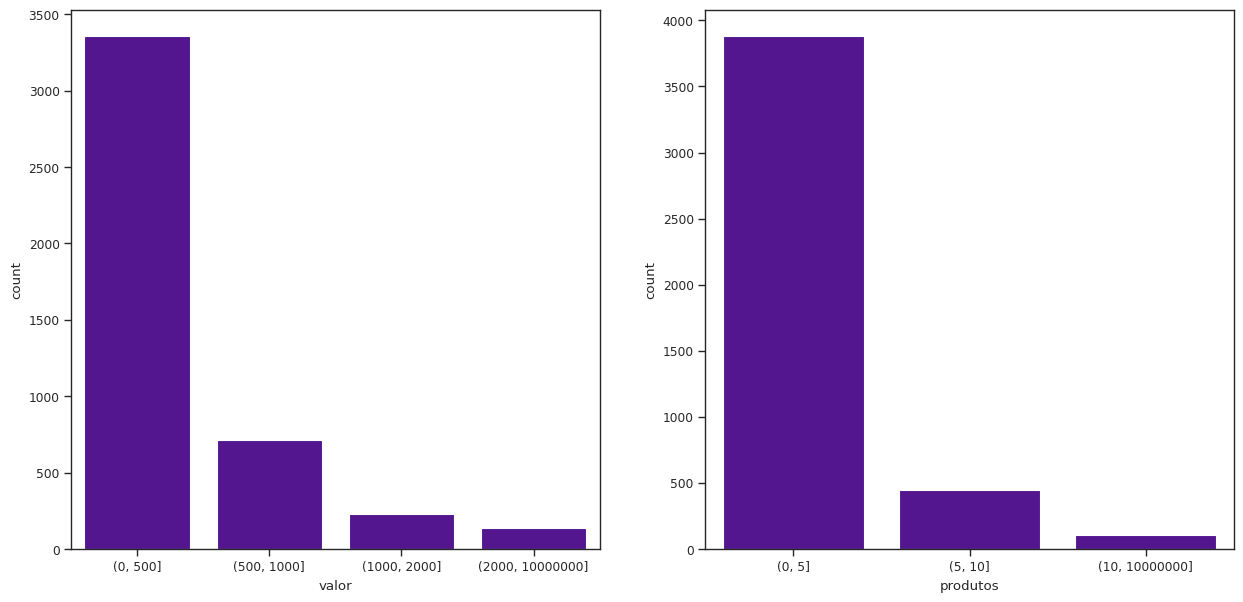

In [25]:
axes = plot.figure(figsize=(15, 7)).subplots(1, 2)

seaborn.countplot(data=pedidos, x='valor', order=sort_by_range(pedidos.valor.dropna().unique()), ax=axes[0])
seaborn.countplot(data=pedidos, x='produtos', order=sort_by_range(pedidos.produtos.dropna().unique()), ax=axes[1])

Outras variáveis categóricas:

<Axes: xlabel='count', ylabel='fonte_cliente'>

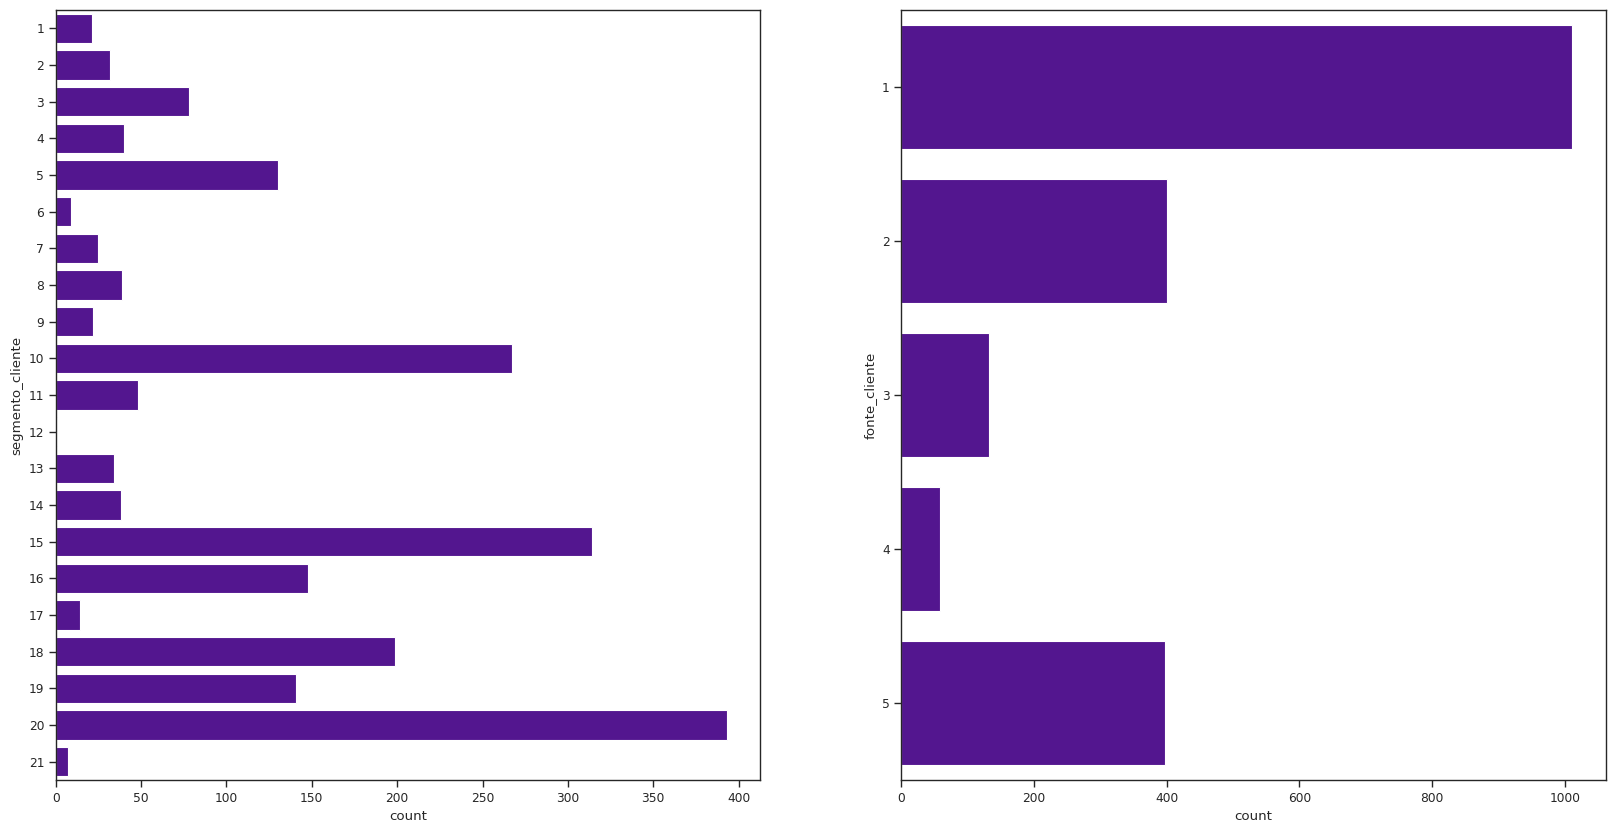

In [26]:
get_number = lambda str: str.split(' ')[1]
segmentos = leads.segmento_cliente.map(get_number)
fontes = leads.fonte_cliente.map(get_number)

ax1, ax2 = plot.figure(figsize=(20, 10)).subplots(1, 2)

seaborn.countplot(data=segmentos.sort_values(key=lambda arr: arr.astype(int)), ax=ax1)
seaborn.countplot(data=fontes.sort_values(key=lambda arr: arr.astype(int)), ax=ax2)

<Axes: xlabel='count', ylabel='ifood_faixa_preco'>

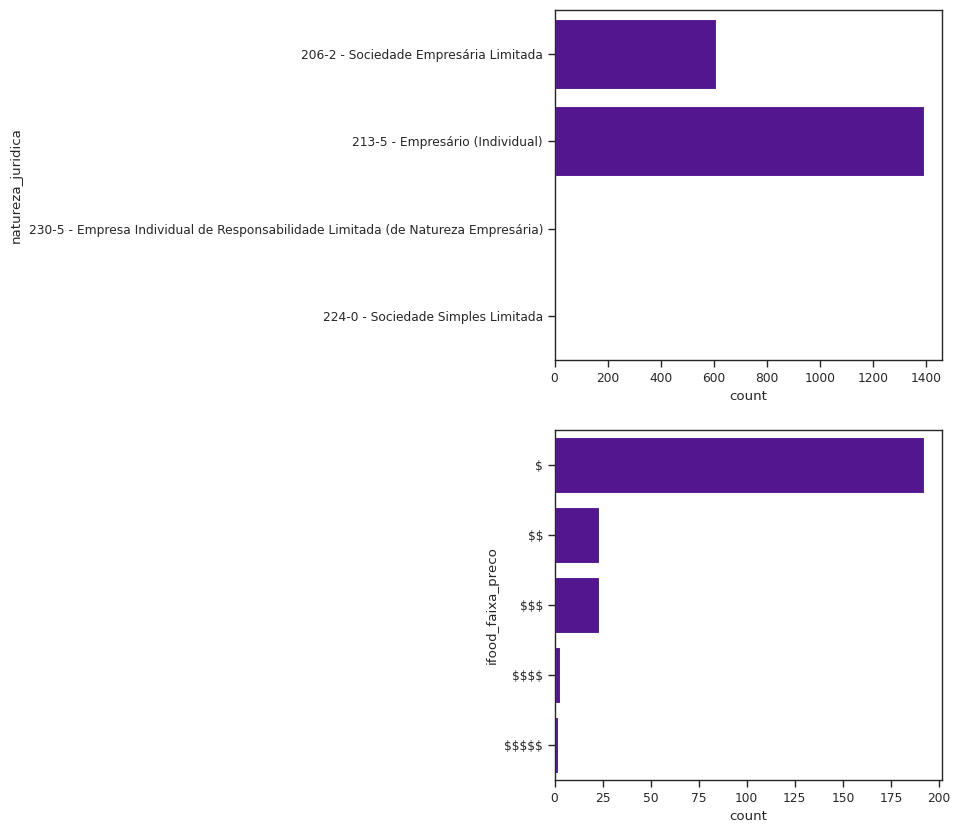

In [27]:
ax1, ax2 = plot.figure(figsize=(5, 10)).subplots(2, 1)

seaborn.countplot(data=leads.natureza_juridica, ax=ax1)
# esse map é pq aparentemente $ é um caracter especial no matplotlib
seaborn.countplot(data=leads.ifood_faixa_preco.dropna().sort_values().map(lambda str: str.replace('$', '\\$')), ax=ax2)

## Análise Bivariada

<Axes: xlabel='churned', ylabel='idade_cnpj'>

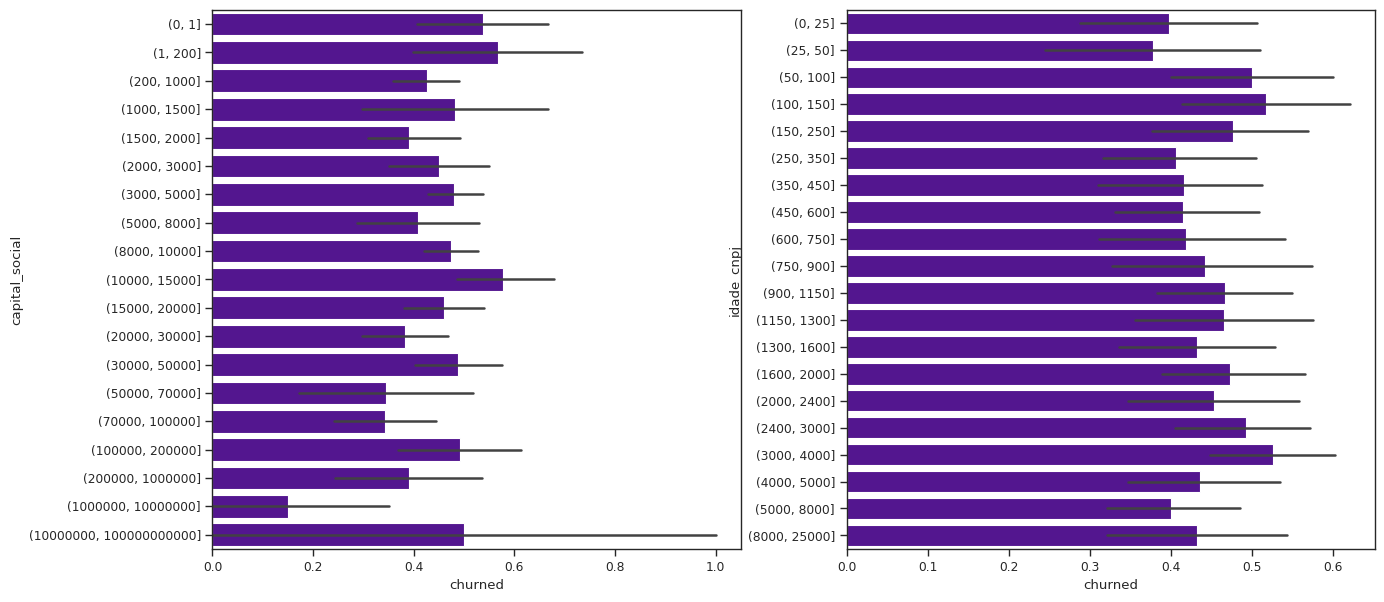

In [34]:
ax1, ax2 = plot.figure(figsize=(15, 7)).subplots(1, 2)
seaborn.barplot(data=leads,x='churned',y='capital_social',order=sort_by_range(leads.capital_social.unique()), ax=ax1)
seaborn.barplot(data=leads,x='churned',y='idade_cnpj',order=sort_by_range(leads.idade_cnpj.unique()), ax=ax2)

> tinha uma hipótese que empresas novas dão mais churn, mas não é uma grande diferença e empresas maiores não dão menos churn

OBS: sobre esse 'risco': é um 'intervalo de confiança' https://seaborn.pydata.org/generated/seaborn.barplot.html

<Axes: xlabel='churned', ylabel='segmento_cliente'>

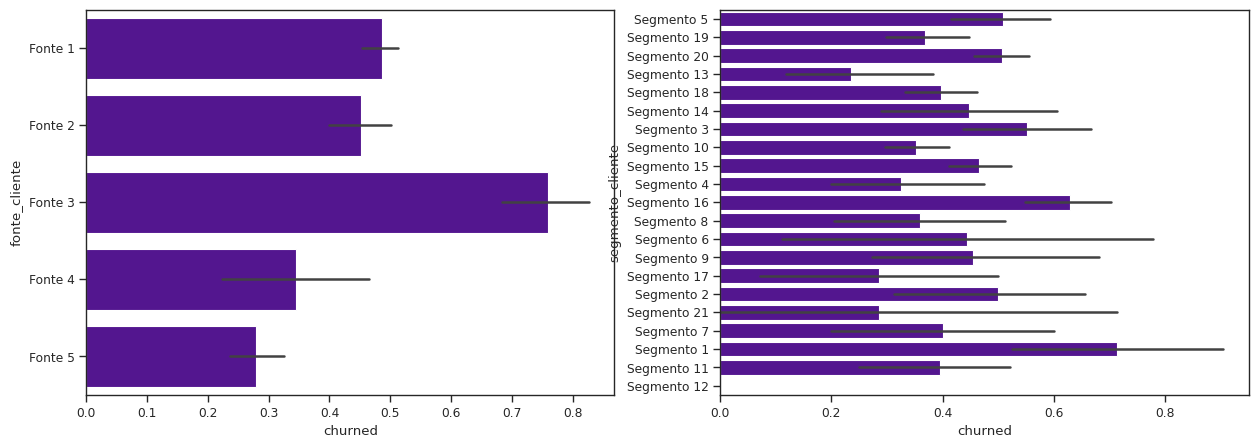

In [59]:
ax1, ax2 = plot.figure(figsize=(15, 5)).subplots(1, 2)
seaborn.barplot(data=leads,x='churned',y='fonte_cliente',order=sorted(leads.fonte_cliente.unique()), ax=ax1)
seaborn.barplot(data=leads,x='churned',y='segmento_cliente',ax=ax2)

> Vou ver em fonte cliente e segmento, mas acho importante ver em relação ao tamanho também

In [36]:
leads.groupby('segmento_cliente').churned.agg(['count']).sort_values('count')

,count
segmento_cliente,
Segmento 12,1
Segmento 21,7
Segmento 6,9
Segmento 17,14
Segmento 1,21
Segmento 9,22
Segmento 7,25
Segmento 2,32
Segmento 13,34


> O Segmente 1 tem a maior taxa de churn, mas tem pouco cliente. Já o segmente 16 tem uma taxa de churn alta também e cerca de 148 clientes

In [37]:
leads.groupby('fonte_cliente').churned.agg(['count']).sort_values('count')

,count
fonte_cliente,
Fonte 4,58
Fonte 3,133
Fonte 5,397
Fonte 2,401
Fonte 1,1011


Text(0.5, 1.0, 'Está no iFood?')

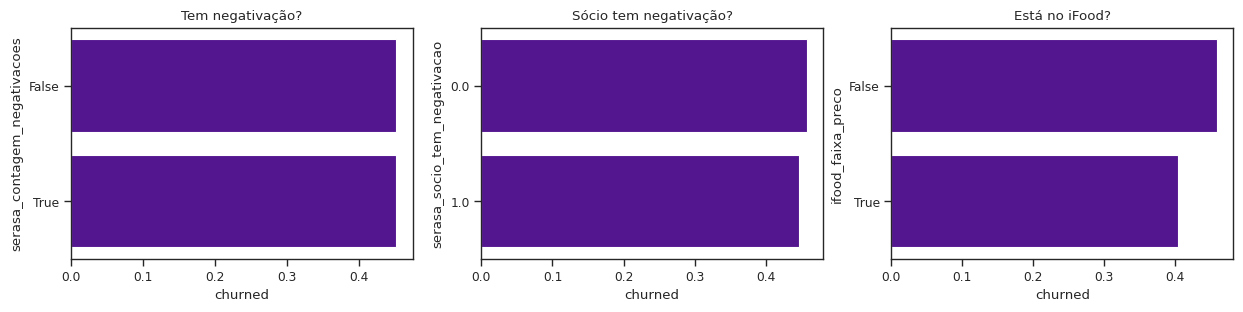

In [38]:
ax1, ax2, ax3 = plot.figure(figsize=(15, 3)).subplots(1, 3)

seaborn.barplot(x=leads.churned, y=leads.serasa_contagem_negativacoes > 0, orient='h',errorbar=None, ax=ax1)
seaborn.barplot(x=leads.churned, y=leads.serasa_socio_tem_negativacao, orient='h',errorbar=None, ax=ax2)
seaborn.barplot(x=leads.churned, y=leads.ifood_faixa_preco.notna(),orient='h',errorbar=None, ax=ax3)

ax1.set_title('Tem negativação?')
ax2.set_title('Sócio tem negativação?')
ax3.set_title('Está no iFood?')

> Pensei que ter negativação de alguma forma iria interferir no churn, mas não é uma diferença grotesca

### Tratamento dos pedidos e variáveis por cliente

Funções de tratamento de faixas e nulos para colunas de pedido

In [39]:
# '(0, 500]' -> 250
def ponto_medio_pedido(faixa):
    if pandas.isna(faixa):
        return np.nan
    baixo, alto = [float(x) for x in faixa.strip('()[]').split(',')]
    if alto >= 10_000_000:        # o teto não significa nada
        return baixo              # usa o limite inferior
    return (baixo + alto) / 2     # faixa fechada - ponto medio

pedidos['valor_num'] = pedidos['valor'].map(ponto_medio_pedido)
pedidos['produtos_num'] = pedidos['produtos'].map(ponto_medio_pedido)

display(pedidos[['valor', 'valor_num']].drop_duplicates().sort_values('valor_num'))
display(pedidos[['produtos', 'produtos_num']].drop_duplicates().sort_values('produtos_num'))


,valor,valor_num
0,"(0, 500]",250.0
4,"(500, 1000]",750.0
27,"(1000, 2000]",1500.0
5,"(2000, 10000000]",2000.0
1754,NaN,NaN


,produtos,produtos_num
0,"(0, 5]",2.5
11,"(5, 10]",7.5
27,"(10, 10000000]",10.0
3603,NaN,NaN


In [40]:
# tratamento dos 3 nulos encontrados
nulos = pedidos['valor_num'].isna() | pedidos['produtos_num'].isna()
print('ANTES:')
display(pedidos.loc[nulos, ['id_pedido', 'id_cliente', 'valor_num', 'produtos_num']])

for coluna in ['valor_num', 'produtos_num']:
    # devolve a mediana do cliente dela
    mediana_do_cliente = pedidos.groupby('id_cliente')[coluna].transform('median')
    pedidos[coluna] = pedidos[coluna].fillna(mediana_do_cliente).fillna(pedidos[coluna].median())

print('DEPOIS:')
display(pedidos.loc[nulos, ['id_pedido', 'id_cliente', 'valor_num', 'produtos_num']])

ANTES:


,id_pedido,id_cliente,valor_num,produtos_num
1754,3651192517370,5284965822687,NaN,2.5
3566,8540620592324,6829726356717,NaN,2.5
3603,9279195172130,8400679696018,NaN,NaN


DEPOIS:


,id_pedido,id_cliente,valor_num,produtos_num
1754,3651192517370,5284965822687,250.0,2.5
3566,8540620592324,6829726356717,250.0,2.5
3603,9279195172130,8400679696018,250.0,2.5


In [41]:
# vários pedidos no mesmo dia contam como 1 dia
pedidos['data'] = pandas.to_datetime(pedidos['data_entrega'])
print('de', pedidos['data'].min().date(), 'até', pedidos['data'].max().date())

de 2024-09-01 até 2024-12-01


Resumir o comportamento de cada cliente

In [60]:
DATA_REF = pedidos['data'].max()

def intervalo_medio(datas):
    dias = datas.drop_duplicates().sort_values()     # só dias distintos, em ordem
    return dias.diff().dt.days.mean()                # diferença entre dias seguidos, em média (NaN se só há 1 dia)

# agrupa os pedidos por cliente e calcula vários resumos de uma vez
por_cliente = pedidos.groupby('id_cliente').agg(
    n_pedidos=('id_pedido', 'count'),
    n_dias_com_pedido=('data', 'nunique'),
    valor_min=('valor_num', 'min'),
    valor_medio=('valor_num', 'mean'),
    valor_mediano=('valor_num', 'median'),
    valor_max=('valor_num', 'max'),
    produtos_min=('produtos_num', 'min'),
    produtos_medio=('produtos_num', 'mean'),
    produtos_mediano=('produtos_num', 'median'),
    produtos_max=('produtos_num', 'max'),
    ultima_data=('data', 'max'),
)

por_cliente['recencia_dias'] = (DATA_REF - por_cliente['ultima_data']).dt.days
por_cliente['intervalo_medio_dias'] = pedidos.groupby('id_cliente')['data'].apply(intervalo_medio)
por_cliente = por_cliente.drop(columns='ultima_data').reset_index()

print('linhas:', len(por_cliente), '| clientes distintos:', por_cliente['id_cliente'].nunique())
por_cliente.head(10)

linhas: 1000 | clientes distintos: 1000


,id_cliente,n_pedidos,n_dias_com_pedido,valor_min,valor_medio,valor_mediano,valor_max,produtos_min,produtos_medio,produtos_mediano,produtos_max,recencia_dias,intervalo_medio_dias
0,1015124383998,5,5,250.0,450.000000,250.0,750.0,2.5,2.500000,2.5,2.5,33,10.000000
1,1015377772889,1,1,250.0,250.000000,250.0,250.0,2.5,2.500000,2.5,2.5,41,NaN
2,1027001713204,13,10,250.0,557.692308,250.0,1500.0,2.5,4.038462,2.5,10.0,21,7.777778
3,1028541889208,5,4,250.0,350.000000,250.0,750.0,2.5,2.500000,2.5,2.5,2,25.666667
4,1048076190944,8,7,250.0,312.500000,250.0,750.0,2.5,2.500000,2.5,2.5,2,14.333333
5,1056896735732,3,3,250.0,250.000000,250.0,250.0,2.5,2.500000,2.5,2.5,18,14.500000
6,1072013408481,8,8,250.0,250.000000,250.0,250.0,2.5,2.500000,2.5,2.5,6,10.000000
7,1074690105832,2,2,250.0,250.000000,250.0,250.0,2.5,2.500000,2.5,2.5,34,6.000000
8,1075117254630,2,2,250.0,500.000000,500.0,750.0,7.5,7.500000,7.5,7.5,4,44.000000
9,1082403104432,13,11,250.0,442.307692,250.0,750.0,2.5,6.346154,7.5,7.5,5,8.300000


In [43]:
base_clientes = leads.merge(por_cliente, on='id_cliente', how='left', validate='one_to_one')

# flag - lead tem pedido ?
base_clientes['tem_pedido'] = base_clientes['n_pedidos'].notna().astype(int)

assert len(base_clientes) == len(leads)        # associa o conjunto de pedidos a um cliente - msm qnt de linhas agr
print('linhas em base_clientes:', len(base_clientes), '| taxa de churn:', round(base_clientes['churned'].mean(), 3))
print('clientes com pedido:', base_clientes['tem_pedido'].sum(), 'de', len(base_clientes))

# só os clientes com pedido
com_pedido = base_clientes[base_clientes['tem_pedido'] == 1]


linhas em base_clientes: 2000 | taxa de churn: 0.452
clientes com pedido: 1000 de 2000


1000 dos clientes não compraram - nulo estrutural tratado com flag

### Bivariada - pedidos vs churn

Variáveis numéricas (de pedidos) comparadas com o churn por Spearman e por faixas

In [44]:
print(base_clientes.groupby('tem_pedido')['churned'].agg(n='count', taxa_churn='mean').round(3))

               n  taxa_churn
tem_pedido                  
0           1000       0.463
1           1000       0.441


In [45]:
colunas = ['n_pedidos', 'n_dias_com_pedido', 'valor_mediano', 'valor_medio', 'valor_max',
           'produtos_mediano', 'produtos_medio', 'produtos_max', 'recencia_dias', 'intervalo_medio_dias']

# Spearman de cada variável com o churn
# positivo - quanto maior a variável, mais churn | negativo - quanto maior a variável, menos churn
linhas = []
for coluna in colunas:
    dados = com_pedido[[coluna, 'churned']].dropna()
    rho, p = stats.spearmanr(dados[coluna], dados['churned'])
    linhas.append({'variável': coluna, 'n': len(dados), 'Spearman': rho, 'p-valor': p})

pandas.DataFrame(linhas).set_index('variável').sort_values('Spearman', key=abs, ascending=False).round(3)

,n,Spearman,p-valor
variável,,,
n_pedidos,1000,-0.498,0.000
n_dias_com_pedido,1000,-0.498,0.000
recencia_dias,1000,0.444,0.000
produtos_max,1000,-0.196,0.000
valor_max,1000,-0.179,0.000
produtos_medio,1000,-0.176,0.000
intervalo_medio_dias,694,0.157,0.000
valor_medio,1000,-0.140,0.000
valor_mediano,1000,-0.038,0.228


- As variáveis com maior relação com o churn são `n_pedidos` (Spearman ≈ −0,50), `n_dias_com_pedido` (≈ −0,50) e `recencia_dias` (≈ +0,44) - quem compra pouco e há muito tempo tende a dar churn.

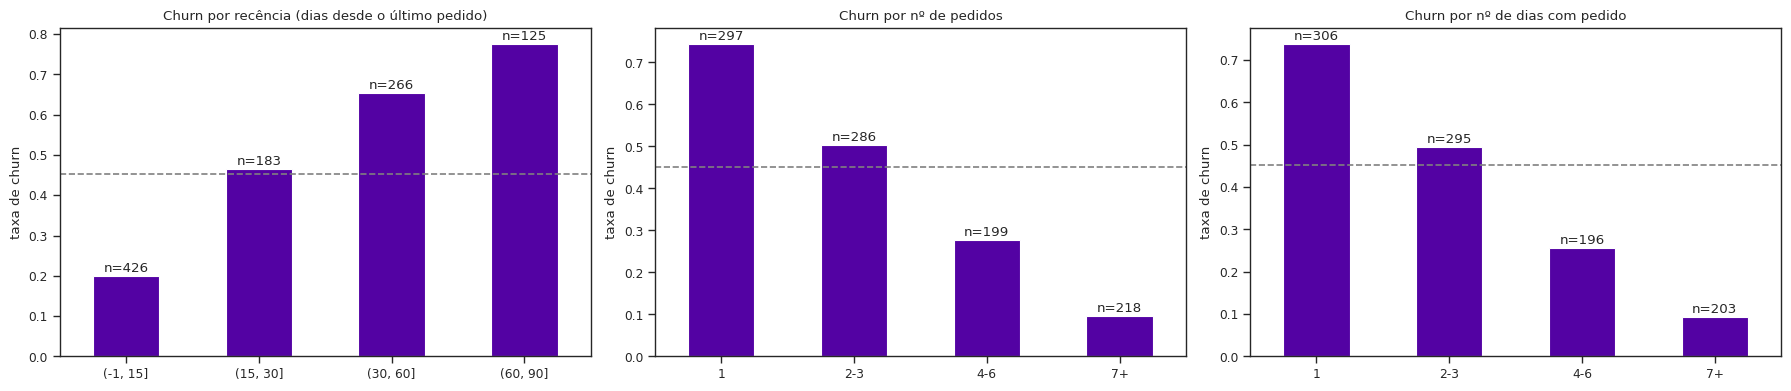

In [46]:
com_pedido = com_pedido.copy()

com_pedido['faixa_recencia'] = pandas.cut(com_pedido['recencia_dias'], [-1, 15, 30, 60, 90])
com_pedido['faixa_pedidos'] = pandas.cut(com_pedido['n_pedidos'], [0, 1, 3, 6, 100], labels=['1', '2-3', '4-6', '7+'])
com_pedido['faixa_dias'] = pandas.cut(com_pedido['n_dias_com_pedido'], [0, 1, 3, 6, 100], labels=['1', '2-3', '4-6', '7+'])

fig, axes = plot.subplots(1, 3, figsize=(18, 4))
for ax, coluna, titulo in [(axes[0], 'faixa_recencia', 'Churn por recência (dias desde o último pedido)'),
                           (axes[1], 'faixa_pedidos', 'Churn por nº de pedidos'),
                           (axes[2], 'faixa_dias', 'Churn por nº de dias com pedido')]:
    tabela = com_pedido.groupby(coluna, observed=True)['churned'].agg(n='count', taxa='mean')
    tabela['taxa'].plot(kind='bar', ax=ax, rot=0)
    ax.axhline(leads['churned'].mean(), color='gray', linestyle='--')    # linha tracejada = taxa geral dos leads
    for i, (n, taxa) in enumerate(zip(tabela['n'], tabela['taxa'])):
        ax.text(i, taxa + 0.01, f'n={n}', ha='center')
    ax.set_title(titulo)
    ax.set_xlabel('')
    ax.set_ylabel('taxa de churn')
plot.tight_layout()
plot.show()

Dá para perceber que n_pedidos e n_dias_com_pedido são bastante correlacionadas, e, portanto, redundantes.

### Bivariada: cadastro vs churn

Variáveis categóricas (do cadastro) comparadas com o churn: taxa de churn de cada categoria e teste qui-quadrado. `p < 0,05` indica relação com o churn. 

In [47]:
def analise_categorica(coluna, minimo=30):
    serie = leads[coluna].astype(str)
    contagem = serie.value_counts()
    serie = serie.where(serie.map(contagem) >= minimo, 'Outras')     # categorias com poucos leads viram 'Outras'

    # quantos leads e qual a taxa de churn de cada categoria
    tabela = leads.groupby(serie)['churned'].agg(leads='count', taxa_churn='mean')
    tabela['taxa_churn'] = (tabela['taxa_churn'] * 100).round(1)

    # qui-quadrado
    p = stats.chi2_contingency(pandas.crosstab(serie, leads['churned']))[1]
    conclusao = 'há relação com o churn' if p < 0.05 else 'sem relação clara com o churn'
    print(f'{coluna}: p-valor = {p:.4f} -> {conclusao}')

    return tabela.sort_values('taxa_churn', ascending=False)

In [48]:
display(analise_categorica('fonte_cliente'))
display(analise_categorica('segmento_cliente'))

fonte_cliente: p-valor = 0.0000 -> há relação com o churn


,leads,taxa_churn
fonte_cliente,,
Fonte 3,133,75.9
Fonte 1,1011,48.6
Fonte 2,401,45.1
Fonte 4,58,34.5
Fonte 5,397,28.0


segmento_cliente: p-valor = 0.0000 -> há relação com o churn


,leads,taxa_churn
segmento_cliente,,
Segmento 16,148,62.8
Segmento 3,78,55.1
Segmento 5,130,50.8
Segmento 20,393,50.6
Segmento 2,32,50.0
Segmento 15,314,46.5
Outras,99,45.5
Segmento 14,38,44.7
Segmento 18,199,39.7


In [49]:
leads['cnae_divisao'] = leads['cnae_codigo'].str[:2]      # 2 primeiros dígitos = divisão

display(analise_categorica('natureza_juridica'))
display(analise_categorica('idade_cnpj'))
display(analise_categorica('cnae_divisao'))

natureza_juridica: p-valor = 0.0042 -> há relação com o churn


,leads,taxa_churn
natureza_juridica,,
213-5 - Empresário (Individual),1390,47.4
206-2 - Sociedade Empresária Limitada,607,40.4
Outras,3,0.0


idade_cnpj: p-valor = 0.8056 -> sem relação clara com o churn


,leads,taxa_churn
idade_cnpj,,
"(3000, 4000]",156,52.6
"(100, 150]",87,51.7
"(50, 100]",100,50.0
"(2400, 3000]",126,49.2
"(150, 250]",109,47.7
"(1600, 2000]",131,47.3
"(1150, 1300]",73,46.6
"(900, 1150]",133,46.6
"(2000, 2400]",95,45.3


cnae_divisao: p-valor = 0.0000 -> há relação com o churn


,leads,taxa_churn
cnae_divisao,,
77,387,50.1
53,1225,47.0
Outras,91,42.9
39,265,32.8
74,32,25.0
